### **0. Environment Setup**

In [1]:
#Import Libs
import sklearn
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler

In [2]:
#Define Colors Palette and Standards for Illustrations
RED, DARK, GRAY, LIGHT, SOFT = "#CD2027", "#404040", "#7F7F7F", "#D9D9D9", "#E9A0A3"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams.update({
    "figure.figsize": (7.5, 4.2),
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.prop_cycle": cycler(color=[RED, DARK, SOFT, GRAY]),
})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

In [3]:
#Helper Functions: Evaluation Reports ( Confusion Matrix, Metrics, ROC and Precision-Recall )
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, log_loss, matthews_corrcoef,
                             confusion_matrix, roc_curve, precision_recall_curve)

def plot_confusion(cm, labels, ax, title="Confusion matrix"):
    ax.imshow(cm, cmap="Reds"); ax.grid(False)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45 if len(labels) > 4 else 0, ha="right" if len(labels) > 4 else "center")
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=10 if len(labels) > 4 else 13,
                    color="white" if cm[i, j] > cm.max() / 2 else DARK)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)

def report_binary(y_true, y_pred, y_score, name="model", labels=("negative", "positive"), plot=True):
    """Confusion matrix, ROC and Precision-Recall curves + a Series with the main metrics (positive class = 1)."""
    y_true, y_pred, y_score = np.asarray(y_true), np.asarray(y_pred), np.asarray(y_score)
    metrics = {"accuracy": accuracy_score(y_true, y_pred), "balanced acc.": balanced_accuracy_score(y_true, y_pred),
               "precision": precision_score(y_true, y_pred, zero_division=0), "recall": recall_score(y_true, y_pred),
               "F1": f1_score(y_true, y_pred), "MCC": matthews_corrcoef(y_true, y_pred),
               "ROC AUC": roc_auc_score(y_true, y_score), "PR AUC": average_precision_score(y_true, y_score)}
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
        plot_confusion(confusion_matrix(y_true, y_pred), list(labels), axes[0], f"Confusion matrix – {name}")
        fpr, tpr, _ = roc_curve(y_true, y_score)
        axes[1].plot(fpr, tpr, color=RED, lw=2.4, label=f"AUC = {metrics['ROC AUC']:.3f}"); axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--")
        axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate"); axes[1].set_title("ROC curve"); axes[1].legend(loc="lower right")
        p, r, _ = precision_recall_curve(y_true, y_score)
        axes[2].plot(r, p, color=DARK, lw=2.4, label=f"AP = {metrics['PR AUC']:.3f}"); axes[2].axhline(y_true.mean(), color=GRAY, ls="--")
        axes[2].set_xlabel("recall"); axes[2].set_ylabel("precision"); axes[2].set_title("Precision–Recall curve"); axes[2].legend(loc="lower left")
        plt.tight_layout(); plt.show()
    return pd.Series(metrics, name=name)

def report_multiclass(y_true, y_pred, y_proba, labels, name="model", plot=True):
    """Confusion matrix, one-vs-rest ROC curves and per-class F1 + a Series with the main metrics."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    k = len(labels)
    metrics = {"accuracy": accuracy_score(y_true, y_pred), "balanced acc.": balanced_accuracy_score(y_true, y_pred),
               "macro precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
               "macro recall": recall_score(y_true, y_pred, average="macro"), "macro F1": f1_score(y_true, y_pred, average="macro"),
               "MCC": matthews_corrcoef(y_true, y_pred), "ROC AUC (ovr)": roc_auc_score(y_true, y_proba, multi_class="ovr"),
               "log loss": log_loss(y_true, y_proba, labels=list(range(k)))}
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.1, 1, 1]})
        plot_confusion(confusion_matrix(y_true, y_pred, labels=list(range(k))), list(labels), axes[0], f"Confusion matrix – {name}")
        cmap = plt.get_cmap("tab10")
        for c in range(k):
            fpr, tpr, _ = roc_curve((y_true == c).astype(int), y_proba[:, c])
            axes[1].plot(fpr, tpr, color=cmap(c), lw=1.6, label=f"{labels[c]}")
        axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--"); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
        axes[1].set_title(f"ROC one-vs-rest (macro AUC = {metrics['ROC AUC (ovr)']:.3f})"); axes[1].legend(fontsize=7, ncol=2 if k > 5 else 1, loc="lower right")
        f1s = f1_score(y_true, y_pred, average=None)
        axes[2].bar(range(k), f1s, color=RED, width=0.65); axes[2].set_xticks(range(k)); axes[2].set_xticklabels(labels, rotation=45 if k > 4 else 0, ha="right" if k > 4 else "center")
        axes[2].set_ylim(0, 1.05); axes[2].set_ylabel("F1"); axes[2].set_title("F1 per class")
        plt.tight_layout(); plt.show()
    return pd.Series(metrics, name=name)
def annotate_heatmap(ax, mat, fmt="{:.2f}"):
    """Write the values on an imshow heat map with a readable text color."""
    mat = np.asarray(mat, dtype=float)
    lo, hi = np.nanmin(mat), np.nanmax(mat)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat[i, j]
            ax.text(j, i, "–" if np.isnan(v) else fmt.format(v), ha="center", va="center", color="white" if (not np.isnan(v) and v > (lo + hi) / 2) else DARK)

### **1. Rule-Based Techniques**

Models whose knowledge is a set of **IF ⟶ THEN** rules: transparent, auditable and easy to explain.

| Technique | Where the rules come from | Idea |
|---|---|---|
| **CN2** | learned from data | ordered rule list built by beam search (entropy + significance test) |
| **Expert system** | written by specialists | inference engine + knowledge base, with certainty factors |
| **Case-Based Reasoning** | no explicit rules: past **cases** | retrieve · reuse · revise · retain |
| **Apriori (CBA)** | mined from data | class association rules: frequent itemsets → class |

All four are applied to the same problem: **malignant × benign** tumours (Breast Cancer dataset).

### **2. Dataset and Preparation**

* Positive class = **malignant** (1) · 10 *mean* attributes (readable rules)
* Train/test split **70/30**, stratified
* For CN2 and Apriori the attributes are **discretised** in 3 quantile bins (*low / mid / high*), fitted on the **training set only**

In [4]:
#Load the Breast Cancer Dataset ( Positive Class = Malignant )
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

data = load_breast_cancer(as_frame=True)
cols = [c for c in data.data.columns if c.startswith("mean ")]            # 10 "mean" attributes
X = data.data[cols]
y = (data.target == 0).astype(int)                                        # 1 = malignant, 0 = benign
CLASS_NAMES = ["benign", "malignant"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)
print("train:", X_train.shape, "| test:", X_test.shape, "| malignant in train:", f"{y_train.mean():.1%}")
X_train.head(3)

train: (398, 10) | test: (171, 10) | malignant in train: 37.2%


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension
78,20.18,23.97,143.70,1245.0,0.129,0.345,0.375,0.160,0.291,0.081
330,16.03,15.51,105.80,793.2,0.095,0.137,0.120,0.070,0.178,0.060
378,13.66,15.15,88.27,580.6,0.083,0.075,0.042,0.025,0.179,0.059


In [5]:
#Discretise the Attributes ( Quantile Bins Fitted on the Training Set )
from sklearn.preprocessing import KBinsDiscretizer

disc = KBinsDiscretizer(n_bins=3, encode="ordinal", strategy="quantile", quantile_method="averaged_inverted_cdf").fit(X_train)
LEVELS = np.array(["low", "mid", "high"])

def to_categorical(Xnum):
    codes = disc.transform(Xnum).astype(int)
    return pd.DataFrame(LEVELS[codes], columns=[c.replace("mean ", "") for c in Xnum.columns], index=Xnum.index)

Xc_train, Xc_test = to_categorical(X_train), to_categorical(X_test)
Xc_train.head(3)

,radius,texture,perimeter,area,smoothness,compactness,concavity,concave points,symmetry,fractal dimension
78,high,high,high,high,high,high,high,high,high,high
330,high,low,high,high,mid,high,high,high,mid,mid
378,mid,low,mid,mid,low,mid,mid,mid,mid,mid


### **3. CN2 Rule Induction**

CN2 (Clark & Niblett, 1989) learns an **ordered rule list**:

1. **Beam search** for the best *complex* (conjunction of `attribute = value`) using **entropy** of the covered examples
2. Keep it only if it is **statistically significant** (likelihood-ratio statistic, $\chi^2$ test)
3. Add the rule (majority class of the covered examples), **remove** the covered examples and repeat
4. Finish with a **default rule**

$$\text{LRS} = 2 \sum_i f_i \ln \frac{f_i}{e_i} \qquad \text{entropy} = -\sum_i p_i \log_2 p_i$$

In [6]:
#CN2 Implementation ( Ordered Rule List with Beam Search, Entropy and Likelihood-Ratio Significance )
from scipy.stats import chi2

class CN2:
    def __init__(self, beam_width=5, max_len=4, alpha=0.05, min_cover=5):
        self.beam_width, self.max_len, self.alpha, self.min_cover = beam_width, max_len, alpha, min_cover

    @staticmethod
    def _entropy(counts):
        p = counts[counts > 0] / counts.sum()
        return -(p * np.log2(p)).sum()

    @staticmethod
    def _lrs(counts, prior):
        expected, m = prior * counts.sum(), counts > 0
        return 2 * (counts[m] * np.log(counts[m] / expected[m])).sum()

    def fit(self, X, y):
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        yi, k = np.searchsorted(self.classes_, y), len(self.classes_)
        selectors = [(c, v) for c in X.columns for v in sorted(X[c].unique())]
        masks = {s: (X[s[0]] == s[1]).to_numpy() for s in selectors}
        crit = chi2.ppf(1 - self.alpha, k - 1)
        remaining, self.rules_ = np.ones(len(X), bool), []
        while remaining.sum() > 0:
            prior = np.bincount(yi[remaining], minlength=k) / remaining.sum()
            best, best_ent, star = None, np.inf, [()]
            for depth in range(1, self.max_len + 1):
                cands = {}
                for cx in star:
                    used = {a for a, _ in cx}
                    for s in selectors:
                        if s[0] in used:
                            continue
                        new = tuple(sorted(cx + (s,)))
                        if new in cands:
                            continue
                        m = remaining.copy()
                        for sel in new:
                            m &= masks[sel]
                        if m.sum() < self.min_cover:
                            continue
                        counts = np.bincount(yi[m], minlength=k)
                        cands[new] = (self._entropy(counts), counts)
                if not cands:
                    break
                ranked = sorted(cands.items(), key=lambda kv: (kv[1][0], -kv[1][1].sum()))
                for cx, (ent, counts) in ranked:
                    if ent < best_ent and self._lrs(counts, prior) > crit:
                        best, best_ent = cx, ent
                star = [cx for cx, _ in ranked[:self.beam_width]]
            if best is None:
                break
            m = remaining.copy()
            for sel in best:
                m &= masks[sel]
            counts = np.bincount(yi[m], minlength=k)
            self.rules_.append({"conds": best, "cls": int(counts.argmax()), "counts": counts, "lrs": self._lrs(counts, prior)})
            remaining &= ~m
        default_counts = np.bincount(yi[remaining], minlength=k) if remaining.sum() else np.bincount(yi, minlength=k)
        self.default_ = {"conds": (), "cls": int(default_counts.argmax()), "counts": default_counts, "lrs": np.nan}
        return self

    def _rule_mask(self, X, rule):
        m = np.ones(len(X), bool)
        for a, v in rule["conds"]:
            m &= (X[a] == v).to_numpy()
        return m

    def predict_proba(self, X):
        k = len(self.classes_)
        proba, free = np.zeros((len(X), k)), np.ones(len(X), bool)
        for rule in self.rules_ + [self.default_]:
            m = self._rule_mask(X, rule) & free
            proba[m] = (rule["counts"] + 1) / (rule["counts"].sum() + k)           # Laplace estimate
            free &= ~m
        return proba

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

    def rules_table(self):
        rows = []
        for i, r in enumerate(self.rules_ + [self.default_], 1):
            text = " AND ".join(f"{a}={v}" for a, v in r["conds"]) or "(default)"
            rows.append({"#": i, "IF": text, "THEN": CLASS_NAMES[self.classes_[r["cls"]]], "covers": int(r["counts"].sum()),
                         "precision": r["counts"][r["cls"]] / r["counts"].sum(), "LRS": r["lrs"], "length": len(r["conds"])})
        return pd.DataFrame(rows).set_index("#")

In [7]:
#Fit CN2 and Show the Learned Rule List
cn2 = CN2(beam_width=5, max_len=4, alpha=0.05, min_cover=5).fit(Xc_train, y_train)
rules_df = cn2.rules_table()
print(f"{len(cn2.rules_)} rules + default rule")
rules_df

21 rules + default rule


,IF,THEN,covers,precision,LRS,length
#,,,,,,
1,concave points=low AND perimeter=low,benign,85,1.000,79.048,2
2,concave points=high AND texture=high,malignant,66,1.000,98.867,2
3,concavity=low AND texture=low,benign,32,1.000,25.820,2
4,area=low AND concavity=mid,benign,32,1.000,30.738,2
5,concave points=low AND symmetry=low,benign,17,1.000,20.208,2
6,area=high AND fractal dimension=high,malignant,11,1.000,15.516,2
7,area=high AND concavity=high AND texture=mid,malignant,23,1.000,35.914,3
8,symmetry=low AND texture=low,benign,9,1.000,8.136,2
9,area=mid AND concave points=mid AND smoothness...,benign,15,1.000,14.841,3


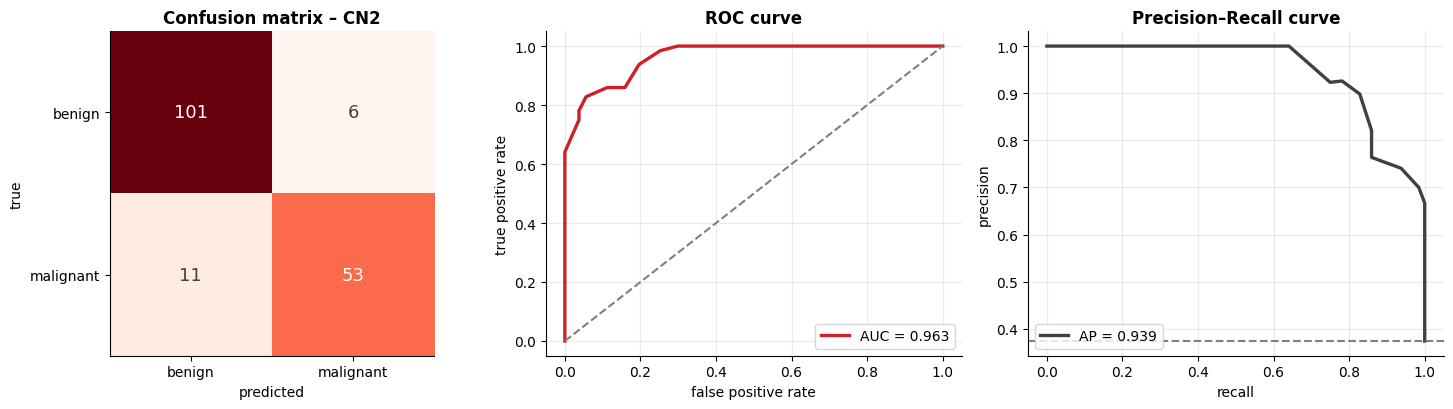

,accuracy,balanced acc.,precision,recall,F1,MCC,ROC AUC,PR AUC
CN2,0.901,0.886,0.898,0.828,0.862,0.786,0.963,0.939


In [8]:
#Evaluate CN2 on the Test Set ( Confusion Matrix, ROC and Precision-Recall )
proba_cn2 = cn2.predict_proba(Xc_test)[:, 1]
pred_cn2 = cn2.predict(Xc_test)
results = {}
results["CN2"] = report_binary(y_test, pred_cn2, proba_cn2, "CN2", CLASS_NAMES)
results["CN2"].to_frame().T

#### **CN2-Specific Metrics**

Rule **coverage** and **precision**, the **significance** (LRS) and the **rule length**. Rules are ordered: each one only sees what the previous ones left uncovered.

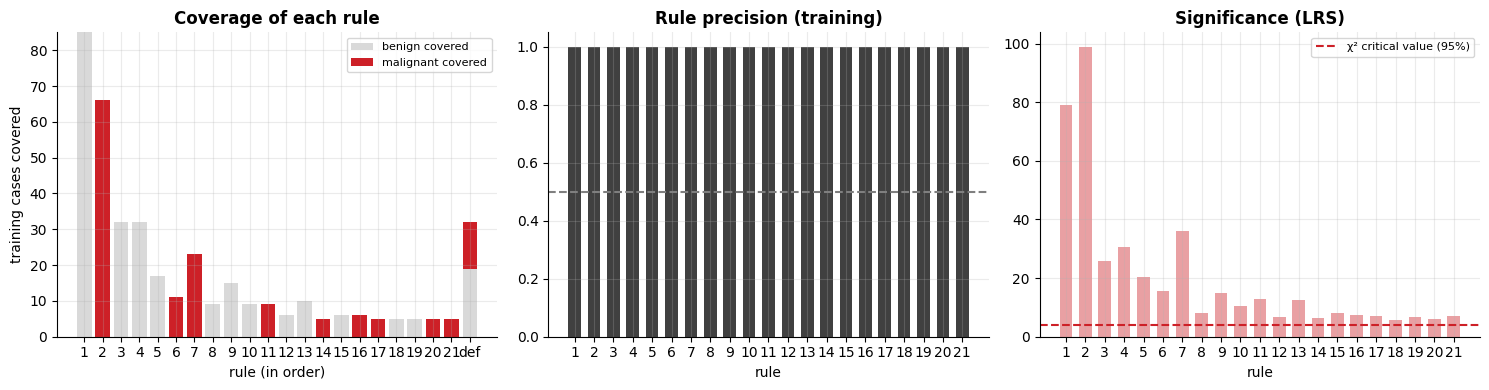

rules: 21 | mean length: 2.57 | rules covering ≥ 90% of one class: 21


In [9]:
#Rule Quality: Coverage by Class, Precision and Significance
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
rr = cn2.rules_ + [cn2.default_]
idx = np.arange(len(rr))
benign_c = [r["counts"][0] for r in rr]; malig_c = [r["counts"][1] for r in rr]
axes[0].bar(idx, benign_c, color=LIGHT, label="benign covered"); axes[0].bar(idx, malig_c, bottom=benign_c, color=RED, label="malignant covered")
axes[0].set_xticks(idx); axes[0].set_xticklabels([str(i + 1) if i < len(cn2.rules_) else "def" for i in idx]); axes[0].set_xlabel("rule (in order)"); axes[0].set_ylabel("training cases covered")
axes[0].set_title("Coverage of each rule"); axes[0].legend(fontsize=8)
axes[1].bar(idx[:-1], rules_df["precision"].iloc[:-1], color=DARK, width=0.65); axes[1].set_ylim(0, 1.05); axes[1].axhline(0.5, color=GRAY, ls="--")
axes[1].set_xticks(idx[:-1]); axes[1].set_xticklabels([str(i + 1) for i in idx[:-1]]); axes[1].set_xlabel("rule"); axes[1].set_title("Rule precision (training)")
axes[2].bar(idx[:-1], rules_df["LRS"].iloc[:-1], color=SOFT, width=0.65); axes[2].axhline(chi2.ppf(0.95, 1), color=RED, ls="--", label="χ² critical value (95%)")
axes[2].set_xticks(idx[:-1]); axes[2].set_xticklabels([str(i + 1) for i in idx[:-1]]); axes[2].set_xlabel("rule"); axes[2].set_title("Significance (LRS)"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"rules: {len(cn2.rules_)} | mean length: {rules_df['length'].iloc[:-1].mean():.2f} | rules covering ≥ 90% of one class: {(rules_df['precision'].iloc[:-1] >= 0.9).sum()}")

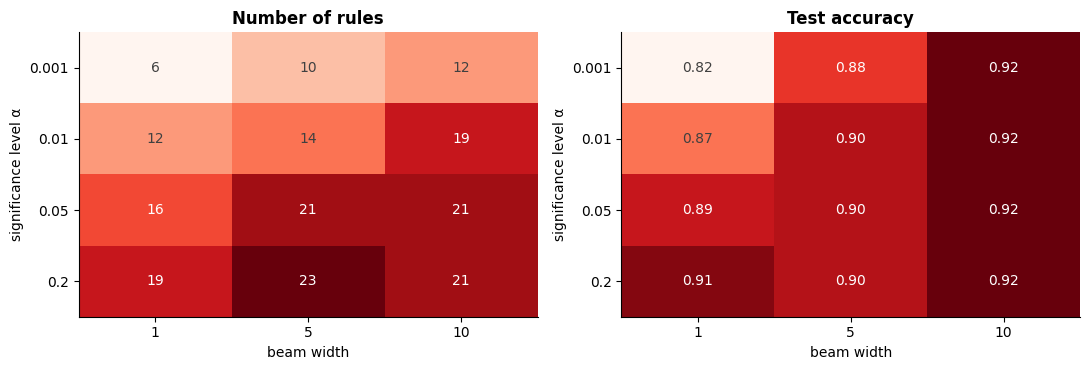

In [10]:
#Sensitivity of CN2: Significance Level and Beam Width
rows = []
for alpha in [0.2, 0.05, 0.01, 0.001]:
    for beam in [1, 5, 10]:
        m = CN2(beam_width=beam, alpha=alpha).fit(Xc_train, y_train)
        rows.append({"alpha": alpha, "beam": beam, "rules": len(m.rules_), "test accuracy": accuracy_score(y_test, m.predict(Xc_test))})
sens = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, title in zip(axes, ["rules", "test accuracy"], ["Number of rules", "Test accuracy"]):
    piv = sens.pivot(index="alpha", columns="beam", values=col)
    ax.imshow(piv, cmap="Reds", aspect="auto"); ax.grid(False)
    ax.set_xticks(range(3)); ax.set_xticklabels(piv.columns); ax.set_yticks(range(4)); ax.set_yticklabels(piv.index)
    ax.set_xlabel("beam width"); ax.set_ylabel("significance level α"); ax.set_title(title)
    annotate_heatmap(ax, piv.to_numpy(), "{:.0f}" if col == "rules" else "{:.2f}")
plt.tight_layout(); plt.show()

A **stricter** α gives **fewer rules** (a simpler list) but, with a narrow beam, loses accuracy (beam 1: ≈ 0.82 at α = 0.001 vs ≈ 0.91 at α = 0.2). A **wider beam** recovers it at a higher search cost.

### **4. Expert Systems**

An expert system separates the **knowledge base** (rules written by specialists) from the **inference engine**.

* **Forward chaining:** facts → rules fire → new facts, until nothing changes
* **Certainty factors (MYCIN):** each rule carries a confidence $CF \in [-1, 1]$; evidence for the same conclusion is combined as $CF = CF_1 + CF_2 (1 - CF_1)$
* **Explanation facility:** the system can show **which rules fired** and why

> The thresholds below are **illustrative** (round values written *a priori*, not learned from the training set) and are **not** clinical advice.

In [11]:
#Knowledge Base and Inference Engine ( Forward Chaining with Certainty Factors )
class ExpertSystem:
    OPS = {">": lambda a, b: a > b, "<": lambda a, b: a < b}

    def __init__(self, rules):
        self.rules = rules                                       # list of dicts: name, if_, then, cf

    def infer(self, case, trace=False):
        facts = {}                                               # working memory: fact -> certainty factor
        log = []
        changed = True
        while changed:
            changed = False
            for r in self.rules:
                if r["name"] in [l["rule"] for l in log]:
                    continue
                ok = all((c[0] in case and self.OPS[c[1]](case[c[0]], c[2])) if c[0] in case else (c[0] in facts and facts[c[0]] > 0)
                         for c in r["if_"])
                if ok:
                    fact = r["then"]
                    old = facts.get(fact, 0.0)
                    facts[fact] = old + r["cf"] * (1 - old) if r["cf"] > 0 else old                    # combine positive evidence
                    log.append({"rule": r["name"], "concludes": fact, "cf": r["cf"]})
                    changed = True
        return (facts, log) if trace else facts

    def score(self, case):
        f = self.infer(case)
        pos, neg = f.get("malignant", 0.0), f.get("benign", 0.0)
        cf = (pos - neg) / (1 - min(abs(pos), abs(neg))) if min(abs(pos), abs(neg)) < 1 else 0.0         # MYCIN combination of opposite evidence
        return (cf + 1) / 2                                                                            # map [-1, 1] -> [0, 1]

knowledge_base = [
    # level 1: measurements -> symptoms (facts)
    {"name": "R1", "if_": [("mean radius", ">", 15)],                      "then": "large_nucleus",   "cf": 1.0},
    {"name": "R2", "if_": [("mean radius", "<", 12)],                      "then": "small_nucleus",   "cf": 1.0},
    {"name": "R3", "if_": [("mean concavity", ">", 0.10)],                 "then": "irregular_shape", "cf": 1.0},
    {"name": "R4", "if_": [("mean concave points", ">", 0.05)],            "then": "irregular_shape", "cf": 1.0},
    {"name": "R5", "if_": [("mean concavity", "<", 0.05)],                 "then": "regular_shape",   "cf": 1.0},
    {"name": "R6", "if_": [("mean area", ">", 800)],                       "then": "large_area",      "cf": 1.0},
    # level 2: symptoms -> diagnosis, with certainty factors
    {"name": "R7",  "if_": [("large_nucleus",), ("irregular_shape",)],     "then": "malignant", "cf": 0.80},
    {"name": "R8",  "if_": [("large_area",)],                              "then": "malignant", "cf": 0.50},
    {"name": "R9",  "if_": [("irregular_shape",)],                         "then": "malignant", "cf": 0.45},
    {"name": "R10", "if_": [("small_nucleus",), ("regular_shape",)],       "then": "benign",    "cf": 0.75},
    {"name": "R11", "if_": [("regular_shape",)],                           "then": "benign",    "cf": 0.40},
    {"name": "R12", "if_": [("small_nucleus",)],                           "then": "benign",    "cf": 0.30},
]
for r in knowledge_base:
    r["if_"] = [c if len(c) == 3 else (c[0], ">", 0) for c in r["if_"]]
es = ExpertSystem(knowledge_base)
print("knowledge base:", len(knowledge_base), "rules")

knowledge base: 12 rules


In [12]:
#Explanation Facility: Why Did the System Decide That? ( First Test Case with 4 or More Rules Fired )
for pos in range(len(X_test)):
    case = X_test.iloc[pos].to_dict()
    facts, log = es.infer(case, trace=True)
    if len(log) >= 4:
        break
print("case:", {k: round(v, 3) for k, v in case.items() if k in ("mean radius", "mean concavity", "mean concave points", "mean area")})
for step in log:
    print(f"  {step['rule']:>3} fired → {step['concludes']:<16} (CF = {step['cf']:.2f})")
print("accumulated certainty:", {k: round(v, 2) for k, v in facts.items() if k in ("malignant", "benign")})
print(f"score(malignant) = {es.score(case):.3f} | true class: {CLASS_NAMES[y_test.iloc[pos]]}")

case: {'mean radius': 7.76, 'mean area': 181.0, 'mean concavity': 0.0, 'mean concave points': 0.0}
   R2 fired → small_nucleus    (CF = 1.00)
   R5 fired → regular_shape    (CF = 1.00)
  R10 fired → benign           (CF = 0.75)
  R11 fired → benign           (CF = 0.40)
  R12 fired → benign           (CF = 0.30)
accumulated certainty: {'benign': 0.9}
score(malignant) = 0.052 | true class: benign


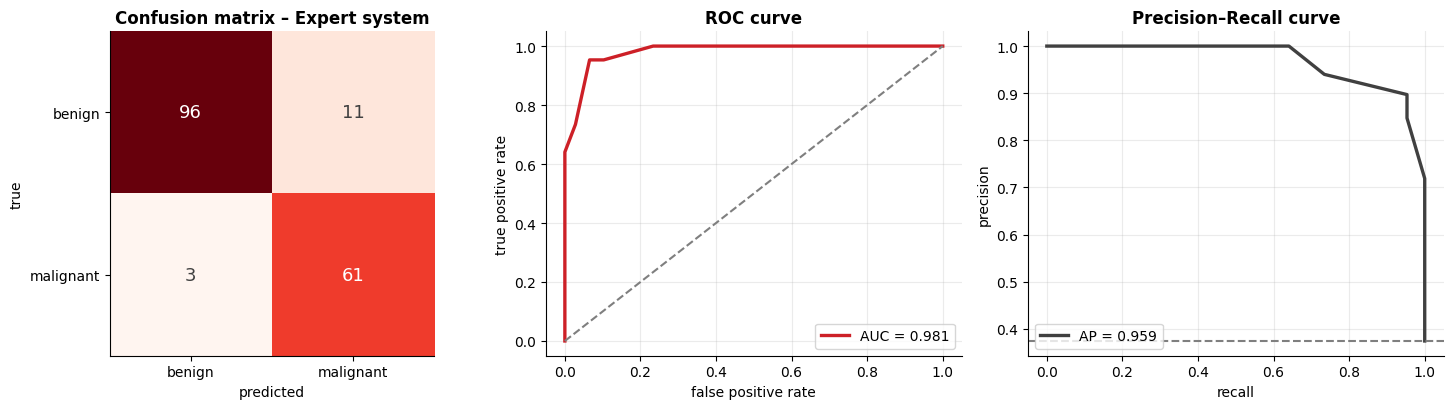

,accuracy,balanced acc.,precision,recall,F1,MCC,ROC AUC,PR AUC
Expert system,0.918,0.925,0.847,0.953,0.897,0.833,0.981,0.959


In [13]:
#Evaluate the Expert System on the Test Set
score_es = np.array([es.score(row) for row in X_test.to_dict("records")])
pred_es = (score_es > 0.5).astype(int)
results["Expert system"] = report_binary(y_test, pred_es, score_es, "Expert system", CLASS_NAMES)
results["Expert system"].to_frame().T

#### **Expert-System-Specific Metrics**

How often each rule **fires**, **coverage** (cases where at least one diagnosis rule fires), **conflicts** (evidence for both classes) and the distribution of the final score.

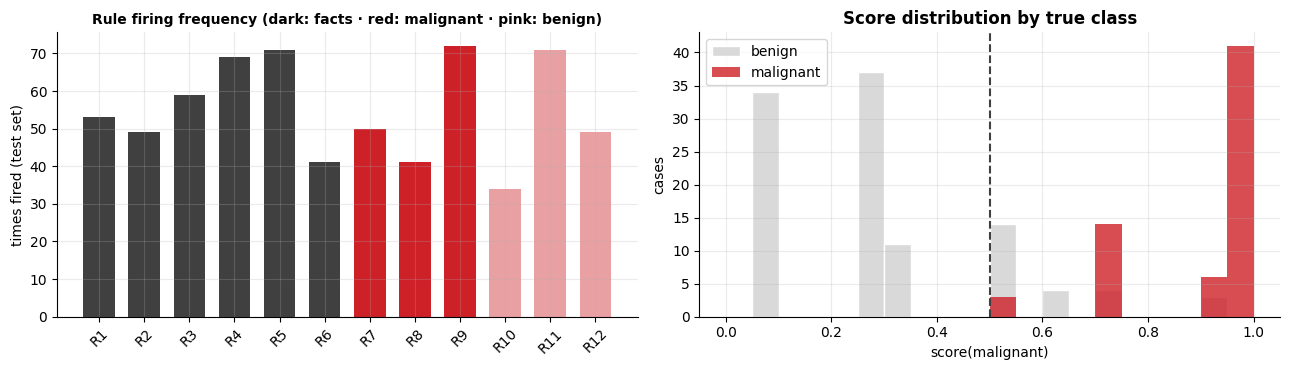

coverage: 90.1% of the cases have a diagnosis | conflicts (evidence for both classes): 2.3%


In [14]:
#Rule Firing Statistics, Coverage and Conflicts
fired = pd.Series(0, index=[r["name"] for r in knowledge_base])
conflict, covered = 0, 0
for row in X_test.to_dict("records"):
    f, log = es.infer(row, trace=True)
    for l in log: fired[l["rule"]] += 1
    covered += int(f.get("malignant", 0) > 0 or f.get("benign", 0) > 0)
    conflict += int(f.get("malignant", 0) > 0 and f.get("benign", 0) > 0)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(fired.index, fired.values, color=[DARK] * 6 + [RED] * 3 + [SOFT] * 3, width=0.7); axes[0].set_ylabel("times fired (test set)")
axes[0].set_title("Rule firing frequency (dark: facts · red: malignant · pink: benign)", fontsize=10); axes[0].tick_params(axis="x", rotation=45)
axes[1].hist(score_es[y_test == 0], bins=20, range=(0, 1), color=LIGHT, edgecolor="white", label="benign")
axes[1].hist(score_es[y_test == 1], bins=20, range=(0, 1), color=RED, alpha=0.8, label="malignant"); axes[1].axvline(0.5, color=DARK, ls="--")
axes[1].set_xlabel("score(malignant)"); axes[1].set_ylabel("cases"); axes[1].set_title("Score distribution by true class"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"coverage: {covered / len(X_test):.1%} of the cases have a diagnosis | conflicts (evidence for both classes): {conflict / len(X_test):.1%}")

### **5. Case-Based Reasoning (CBR)**

There are **no explicit rules**: the knowledge is a **case base**. For a new problem the **CBR cycle** is:

1. **Retrieve:** the most **similar** past cases
2. **Reuse:** adapt their solutions (here, a similarity-weighted vote)
3. **Revise:** check the confidence – low confidence goes to a human
4. **Retain:** store the new, confirmed case when it is useful

In [15]:
#CBR Implementation ( Retrieve, Reuse, Revise, Retain )
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif

class CaseBasedReasoner:
    def __init__(self, k=5, weights=None):
        self.k, self.weights = k, weights

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.scaler_ = StandardScaler().fit(X)
        self.cases_, self.labels_ = self.scaler_.transform(X), np.asarray(y)
        self.w_ = np.ones(X.shape[1]) if self.weights is None else np.asarray(self.weights)
        return self

    def retrieve(self, Xq):                                              # RETRIEVE: weighted distance -> similarity
        Q = self.scaler_.transform(np.asarray(Xq, dtype=float))
        d = np.sqrt((((Q[:, None, :] - self.cases_[None, :, :]) ** 2) * self.w_).sum(axis=2))
        idx = np.argsort(d, axis=1)[:, :self.k]
        return idx, 1 / (1 + np.take_along_axis(d, idx, axis=1))

    def predict_proba(self, Xq):                                         # REUSE: similarity-weighted vote
        idx, sim = self.retrieve(Xq)
        votes = (self.labels_[idx] * sim).sum(axis=1) / sim.sum(axis=1)
        return np.c_[1 - votes, votes]

    def predict(self, Xq):
        return (self.predict_proba(Xq)[:, 1] > 0.5).astype(int)

    def retain(self, x, label):                                          # RETAIN: store the confirmed case
        self.cases_ = np.vstack([self.cases_, self.scaler_.transform(x.reshape(1, -1))]); self.labels_ = np.append(self.labels_, label)

cbr = CaseBasedReasoner(k=5).fit(X_train, y_train)
proba_cbr = cbr.predict_proba(X_test)[:, 1]
print("case base:", cbr.cases_.shape[0], "cases ×", cbr.cases_.shape[1], "attributes")

case base: 398 cases × 10 attributes


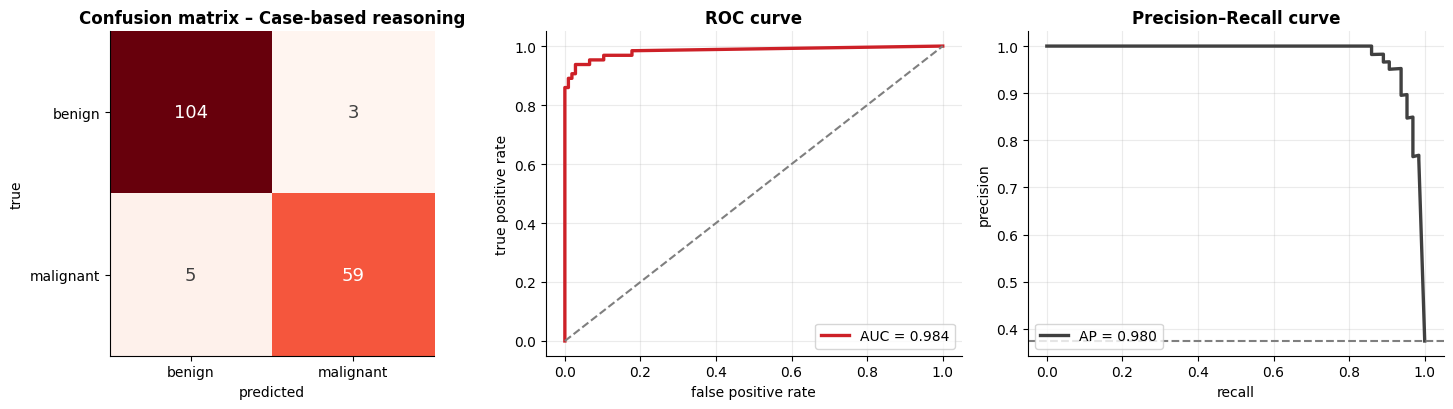

,accuracy,balanced acc.,precision,recall,F1,MCC,ROC AUC,PR AUC
Case-based reasoning,0.953,0.947,0.952,0.922,0.937,0.9,0.984,0.98


In [16]:
#Evaluate CBR on the Test Set
results["CBR"] = report_binary(y_test, cbr.predict(X_test), proba_cbr, "Case-based reasoning", CLASS_NAMES)
results["CBR"].to_frame().T

#### **CBR-Specific Metrics**

* **Retrieval quality:** similarity of the retrieved cases and **precision@k** (share of retrieved cases with the same class as the query)
* **Revise step:** accuracy × **coverage** when low-confidence answers are sent to a human
* **Retain step:** accuracy × **case-base size** under different retention policies

mean similarity of retrieved cases: 0.476 | precision@5: 0.924


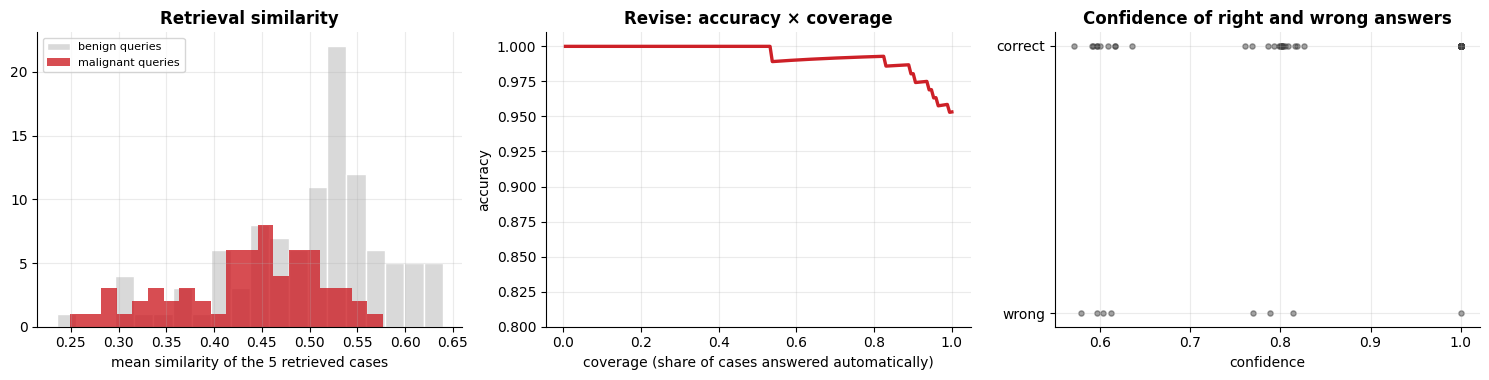

In [17]:
#Retrieval Quality and the Revise Step ( Accuracy x Coverage )
idx, sim = cbr.retrieve(X_test)
precision_at_k = (cbr.labels_[idx] == y_test.to_numpy()[:, None]).mean(axis=1)
print(f"mean similarity of retrieved cases: {sim.mean():.3f} | precision@5: {precision_at_k.mean():.3f}")

conf = np.maximum(proba_cbr, 1 - proba_cbr)                                  # confidence of the answer
order = np.argsort(-conf)
correct = (cbr.predict(X_test) == y_test.to_numpy())[order]
coverage = np.arange(1, len(order) + 1) / len(order)
acc_at_cov = np.cumsum(correct) / np.arange(1, len(order) + 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
axes[0].hist(sim.mean(axis=1)[y_test == 0], bins=20, color=LIGHT, edgecolor="white", label="benign queries")
axes[0].hist(sim.mean(axis=1)[y_test == 1], bins=20, color=RED, alpha=0.8, label="malignant queries"); axes[0].set_xlabel("mean similarity of the 5 retrieved cases"); axes[0].set_title("Retrieval similarity"); axes[0].legend(fontsize=8)
axes[1].plot(coverage, acc_at_cov, color=RED, lw=2.4); axes[1].set_xlabel("coverage (share of cases answered automatically)"); axes[1].set_ylabel("accuracy"); axes[1].set_title("Revise: accuracy × coverage"); axes[1].set_ylim(0.8, 1.01)
axes[2].scatter(conf, correct[np.argsort(order)], s=14, color=DARK, alpha=0.5); axes[2].set_xlabel("confidence"); axes[2].set_yticks([0, 1]); axes[2].set_yticklabels(["wrong", "correct"]); axes[2].set_title("Confidence of right and wrong answers")
plt.tight_layout(); plt.show()

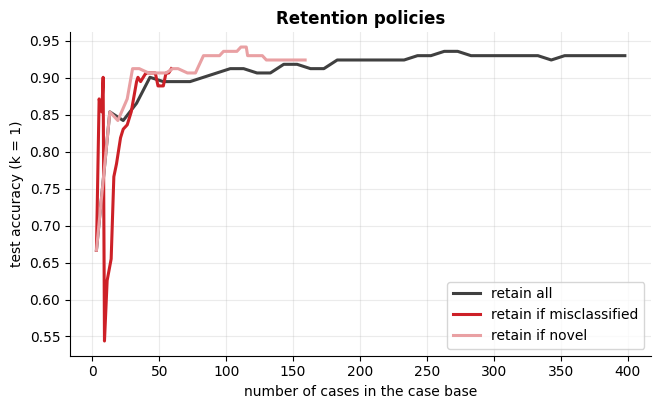

,policy,final case-base size,final test accuracy
0,retain all,398,0.930
1,retain if misclassified,59,0.912
2,retain if novel,159,0.924


In [18]:
#Retain Step: Accuracy x Case-Base Size for Three Retention Policies
rng = np.random.default_rng(RANDOM_STATE)
Xtr_np, ytr_np = X_train.to_numpy(), y_train.to_numpy()
stream = rng.permutation(len(Xtr_np))
seed_ids = [stream[np.where(ytr_np[stream] == c)[0][0]] for c in (0, 1)]                        # start with one case of each class
stream = [i for i in stream if i not in seed_ids]

def run_policy(policy, novelty=1.6):
    model = CaseBasedReasoner(k=1).fit(X_train.iloc[seed_ids], y_train.iloc[seed_ids])
    sizes, accs = [], []
    for step, i in enumerate(stream):
        x, label = Xtr_np[i], ytr_np[i]
        if policy == "retain all":
            keep = True
        else:
            idx, sim = model.retrieve(x.reshape(1, -1)); nearest = model.labels_[idx[0, 0]]
            dist = 1 / sim[0, 0] - 1
            keep = (nearest != label) if policy == "retain if misclassified" else (dist > novelty)
        if keep:
            model.retain(x, label)
        if step % 10 == 0 or step == len(stream) - 1:
            sizes.append(len(model.labels_)); accs.append((model.predict(X_test) == y_test.to_numpy()).mean())
    return np.array(sizes), np.array(accs)

plt.figure()
summary_rows = []
for policy, color in zip(["retain all", "retain if misclassified", "retain if novel"], [DARK, RED, SOFT]):
    s_, a_ = run_policy(policy)
    plt.plot(s_, a_, color=color, lw=2.2, label=policy); summary_rows.append((policy, int(s_[-1]), a_[-1]))
plt.xlabel("number of cases in the case base"); plt.ylabel("test accuracy (k = 1)"); plt.legend(); plt.title("Retention policies")
plt.show()
pd.DataFrame(summary_rows, columns=["policy", "final case-base size", "final test accuracy"])

Retaining **only useful cases** (misclassified or novel) gives a **much smaller** case base for a **small drop** in accuracy – the key to scaling CBR.

In [19]:
#Attribute Weighting ( Mutual Information ) in the Similarity Measure
w = mutual_info_classif(X_train, y_train, random_state=RANDOM_STATE)
w = w / w.max()
cbr_w = CaseBasedReasoner(k=5, weights=w).fit(X_train, y_train)
print(pd.Series(w, index=X_train.columns).round(2).sort_values(ascending=False).head(4).to_dict())
rows = [("unweighted", roc_auc_score(y_test, proba_cbr), accuracy_score(y_test, cbr.predict(X_test))),
        ("weighted by mutual information", roc_auc_score(y_test, cbr_w.predict_proba(X_test)[:, 1]), accuracy_score(y_test, cbr_w.predict(X_test)))]
pd.DataFrame(rows, columns=["similarity", "ROC AUC", "accuracy"])

{'mean concave points': 1.0, 'mean perimeter': 0.91, 'mean radius': 0.86, 'mean area': 0.84}


,similarity,ROC AUC,accuracy
0,unweighted,0.984,0.953
1,weighted by mutual information,0.990,0.953


### **6. Apriori for Classification (Class Association Rules)**

**Associative classification (CBA):** mine **frequent itemsets** that include the class and keep the rules `{attribute values} ⟶ class`.

* **Support:** $P(A \cap C)$ · **Confidence:** $P(C \mid A)$ · **Lift:** $\dfrac{P(C \mid A)}{P(C)}$
* Classifier: rules sorted by **confidence**, then **support**, then **length**; the **first matching rule** decides (otherwise, the default class)

In [20]:
#Apriori Implementation ( Level-wise Search with Join and Prune )
from itertools import combinations

def apriori(B, min_support, max_len=3):
    """B: boolean DataFrame (transactions x items). Returns {itemset (tuple of column names): support}."""
    M_, n, names = B.to_numpy(), len(B), list(B.columns)
    freq = {}
    level = [(i,) for i in range(len(names)) if M_[:, i].mean() >= min_support]
    for c in level:
        freq[c] = M_[:, c[0]].mean()
    k = 1
    while level and k < max_len:
        prev = set(level)
        cands = {a[:-1] + (a[-1], b[-1]) for a in level for b in level if a[:-1] == b[:-1] and a[-1] < b[-1]}          # join
        cands = [c for c in cands if all(sub in prev for sub in combinations(c, k))]                                   # prune
        level = []
        for c in sorted(cands):
            s = M_[:, list(c)].all(axis=1).mean()
            if s >= min_support:
                freq[c] = s; level.append(c)
        k += 1
    return {tuple(names[i] for i in c): s for c, s in freq.items()}

#One-hot "transactions": attribute=value items + the class item
def to_transactions(Xcat, y=None):
    B = pd.get_dummies(Xcat.astype(str).apply(lambda col: col.name + "=" + col)).astype(bool)
    B.columns = [c.split("_", 1)[1] if "_" in c and "=" in c.split("_", 1)[1] else c for c in B.columns]
    if y is not None:
        B["class=" + CLASS_NAMES[0]] = (np.asarray(y) == 0); B["class=" + CLASS_NAMES[1]] = (np.asarray(y) == 1)
    return B

B_train = to_transactions(Xc_train, y_train)
freq = apriori(B_train, min_support=0.05, max_len=3)
print("transactions:", B_train.shape, "| frequent itemsets (support ≥ 5%, size ≤ 3):", len(freq))

transactions: (398, 32) | frequent itemsets (support ≥ 5%, size ≤ 3): 1631


In [21]:
#Generate the Class Association Rules ( Antecedent ⟶ Class )
def class_rules(freq, B, min_conf=0.6):
    class_items = [c for c in B.columns if c.startswith("class=")]
    rows = []
    for itemset, sup in freq.items():
        cls = [i for i in itemset if i.startswith("class=")]
        ante = tuple(i for i in itemset if not i.startswith("class="))
        if len(cls) != 1 or not ante:
            continue
        conf = sup / freq[ante]
        if conf >= min_conf:
            rows.append({"antecedent": ante, "class": cls[0].split("=")[1], "support": sup, "confidence": conf,
                         "lift": conf / freq[(cls[0],)], "length": len(ante)})
    df = pd.DataFrame(rows).sort_values(["confidence", "support", "length"], ascending=[False, False, True]).reset_index(drop=True)
    return df

rules_cba = class_rules(freq, B_train, min_conf=0.6)
print("class association rules (confidence ≥ 60%):", len(rules_cba))
rules_cba.head(8).assign(antecedent=lambda d: d["antecedent"].apply(lambda t: " AND ".join(t)))

class association rules (confidence ≥ 60%): 317


,antecedent,class,support,confidence,lift,length
0,perimeter=low AND concave points=low,benign,0.214,1.0,1.592,2
1,radius=low AND concave points=low,benign,0.209,1.0,1.592,2
2,area=low AND concave points=low,benign,0.209,1.0,1.592,2
3,texture=high AND concave points=high,malignant,0.166,1.0,2.689,2
4,concave points=low AND symmetry=low,benign,0.156,1.0,1.592,2
5,texture=low AND concavity=low,benign,0.146,1.0,1.592,2
6,texture=low AND perimeter=low,benign,0.143,1.0,1.592,2
7,texture=low AND compactness=low,benign,0.141,1.0,1.592,2


rules used (confidence ≥ 80%): 257


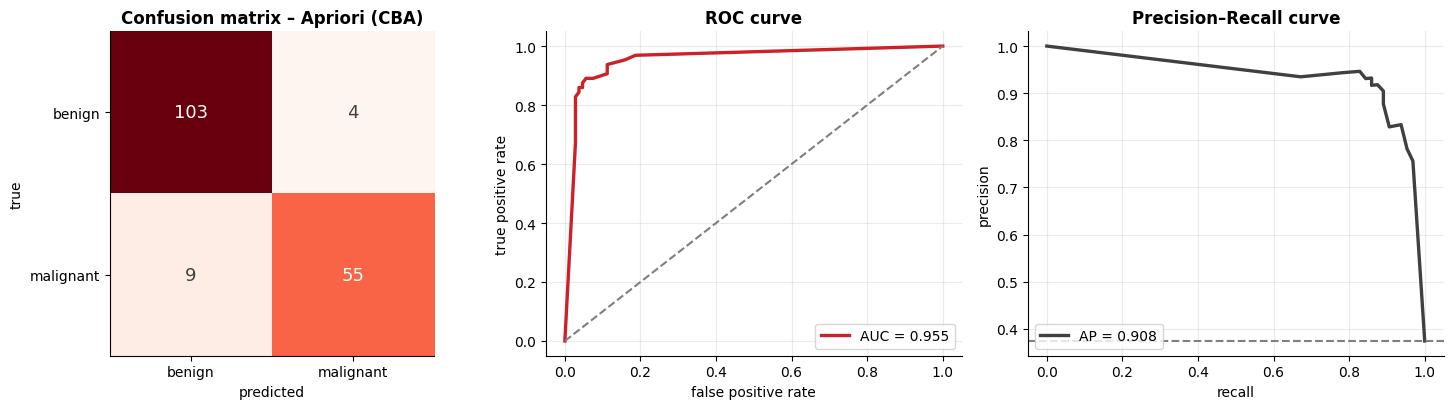

,accuracy,balanced acc.,precision,recall,F1,MCC,ROC AUC,PR AUC
Apriori (CBA),0.924,0.911,0.932,0.859,0.894,0.837,0.955,0.908


In [22]:
#CBA Classifier: First Matching Rule Decides
def cba_predict_proba(rules, Xcat, default_p):
    B = to_transactions(Xcat).reindex(columns=B_train.columns.drop([c for c in B_train.columns if c.startswith("class=")]), fill_value=False)
    p, free = np.full(len(Xcat), default_p, dtype=float), np.ones(len(Xcat), bool)
    for r in rules.itertuples():
        m = B[list(r.antecedent)].all(axis=1).to_numpy() & free
        p[m] = r.confidence if r._2 == CLASS_NAMES[1] else 1 - r.confidence
        free &= ~m
    return p

prior_malignant = y_train.mean()
rules_cba = class_rules(freq, B_train, min_conf=0.8)                      # higher confidence for the classifier
proba_cba = cba_predict_proba(rules_cba, Xc_test, prior_malignant)
pred_cba = (proba_cba > 0.5).astype(int)
print("rules used (confidence ≥ 80%):", len(rules_cba))
results["Apriori (CBA)"] = report_binary(y_test, pred_cba, proba_cba, "Apriori (CBA)", CLASS_NAMES)
results["Apriori (CBA)"].to_frame().T

#### **Apriori-Specific Metrics**

The **quality of each rule** (support, confidence, lift) and how the **thresholds** change the number of rules and the accuracy.

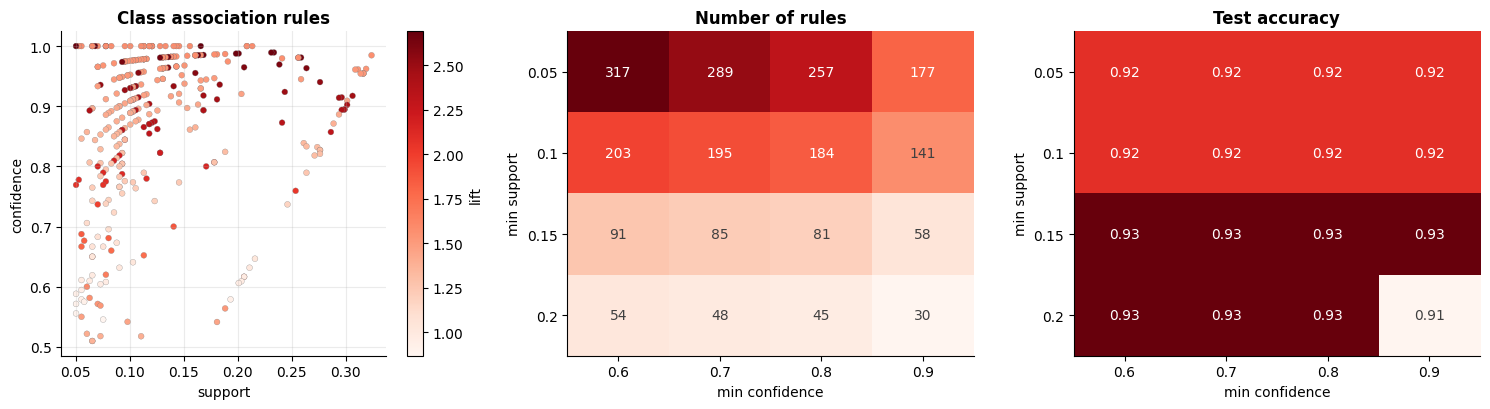

In [23]:
#Rule Quality ( Support x Confidence, Colored by Lift ) and Threshold Sensitivity
all_rules = class_rules(freq, B_train, min_conf=0.5)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sc = axes[0].scatter(all_rules["support"], all_rules["confidence"], c=all_rules["lift"], cmap="Reds", s=18, edgecolor=GRAY, lw=0.2)
axes[0].set_xlabel("support"); axes[0].set_ylabel("confidence"); axes[0].set_title("Class association rules"); fig.colorbar(sc, ax=axes[0], label="lift")

sup_grid, conf_grid = [0.05, 0.1, 0.15, 0.2], [0.6, 0.7, 0.8, 0.9]
n_rules, acc = np.zeros((4, 4), int), np.zeros((4, 4))
for i, s in enumerate(sup_grid):
    for j, c in enumerate(conf_grid):
        r = all_rules[(all_rules["support"] >= s) & (all_rules["confidence"] >= c)]
        n_rules[i, j] = len(r)
        acc[i, j] = accuracy_score(y_test, (cba_predict_proba(r, Xc_test, prior_malignant) > 0.5).astype(int)) if len(r) else np.nan
for ax, mat, title, fmt in [(axes[1], n_rules, "Number of rules", "{:.0f}"), (axes[2], acc, "Test accuracy", "{:.2f}")]:
    ax.imshow(mat, cmap="Reds", aspect="auto"); ax.grid(False)
    ax.set_xticks(range(4)); ax.set_xticklabels(conf_grid); ax.set_yticks(range(4)); ax.set_yticklabels(sup_grid)
    ax.set_xlabel("min confidence"); ax.set_ylabel("min support"); ax.set_title(title)
    annotate_heatmap(ax, mat, fmt)
plt.tight_layout(); plt.show()

### **7. Comparing the Four Techniques**

,accuracy,precision,recall,F1,ROC AUC,PR AUC,knowledge size
CN2,0.901,0.898,0.828,0.862,0.963,0.939,21 rules + default
Expert system,0.918,0.847,0.953,0.897,0.981,0.959,12 rules (written)
CBR,0.953,0.952,0.922,0.937,0.984,0.980,398 cases
Apriori (CBA),0.924,0.932,0.859,0.894,0.955,0.908,257 rules


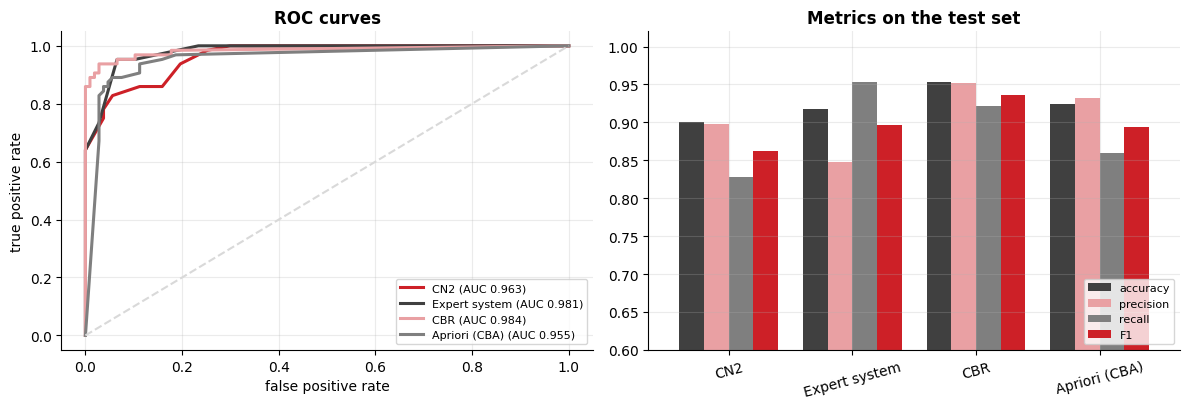

In [24]:
#Comparison Table and ROC Curves of the Four Rule-Based Techniques
scores = {"CN2": proba_cn2, "Expert system": score_es, "CBR": proba_cbr, "Apriori (CBA)": proba_cba}
size = {"CN2": f"{len(cn2.rules_)} rules + default", "Expert system": f"{len(knowledge_base)} rules (written)",
        "CBR": f"{len(cbr.labels_)} cases", "Apriori (CBA)": f"{len(rules_cba)} rules"}
comparison = pd.DataFrame(results).T[["accuracy", "precision", "recall", "F1", "ROC AUC", "PR AUC"]]
comparison["knowledge size"] = pd.Series(size)
display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for (name, s), color in zip(scores.items(), [RED, DARK, SOFT, GRAY]):
    fpr, tpr, _ = roc_curve(y_test, s); axes[0].plot(fpr, tpr, color=color, lw=2.2, label=f"{name} (AUC {roc_auc_score(y_test, s):.3f})")
axes[0].plot([0, 1], [0, 1], color=LIGHT, ls="--"); axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate"); axes[0].set_title("ROC curves"); axes[0].legend(loc="lower right", fontsize=8)
comparison[["accuracy", "precision", "recall", "F1"]].plot.bar(ax=axes[1], color=[DARK, SOFT, GRAY, RED], width=0.8, rot=15)
axes[1].set_ylim(0.6, 1.02); axes[1].set_title("Metrics on the test set"); axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

| | **CN2** | **Expert system** | **CBR** | **Apriori (CBA)** |
|---|---|---|---|---|
| Knowledge | learned rules | human rules | stored cases | mined rules |
| Needs labelled data? | ✅ | ❌ (but needs an expert) | ✅ | ✅ |
| Explains its answer? | ✅ rule | ✅ rule trace | ✅ similar cases | ✅ rule |
| Main risk | few/many rules (overfitting) | knowledge bottleneck | cost of retrieval, case-base size | huge rule sets, thresholds |